# This notebook is dedicated to Splitting the Dataset
1. python scripts from /src will be imported

# preparations - imports

In [ ]:
import duckdb, pandas as pd
from digikala_review_transformer.config import ROOT, DATA_PROCESSED, REPORTS, SPLIT_SEED, DB_PATH, CLEAN_TABLE

con = duckdb.connect(str(DB_PATH))
con.execute("LOAD ui;")
con.execute("CALL start_ui();")

Opening in existing browser session.


[478628:478628:0100/000000.410837:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)
[1:1:0100/000000.420376:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)


## overal review of DB

In [4]:
cur = con.cursor()  # fresh connection to the same DB, avoids the stuck result on `con`

def scalar(query):
    # fetchall() fully consumes the result, so nothing stays open
    return cur.execute(query).fetchall()[0][0]

print(cur.sql("SHOW TABLES").df())
print(cur.sql(f"DESCRIBE {CLEAN_TABLE}").df())

total = scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE}")
print("total rows:", total)

# Rows per product (ORDER BY keeps it deterministic for step 4)
prod = cur.sql(f"""
    SELECT product_id, COUNT(*) AS n_rows
    FROM {CLEAN_TABLE}
    WHERE product_id IS NOT NULL
    GROUP BY product_id
    ORDER BY product_id
""").df()

null_pid = scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE} WHERE product_id IS NULL")

s = prod["n_rows"]
summary = pd.DataFrame([{
    "n_products": len(prod), "null_product_id_rows": null_pid,
    "median": s.median(), "mean": round(s.mean(), 1), "max": s.max(),
    "p90": s.quantile(.90), "p99": s.quantile(.99),
    "max_share_pct": round(100 * s.max() / total, 3),
    "top10_share_pct": round(100 * s.nlargest(10).sum() / total, 3),
}])
print(summary.T)
print(prod.nlargest(10, "n_rows"))

                 name
0   body_backup_latin
1          clean_base
2     defect_manifest
3            dup_plan
4         dup_plan_s3
5          len_sample
6                 raw
7        rule_summary
8      tmp_dup_groups
9         tmp_dup_ids
10       tmp_dup_rows
             column_name    column_type null   key default extra
0               _row_idx         BIGINT  YES  None    None  None
1                     id        VARCHAR  YES  None    None  None
2                  title        VARCHAR  YES  None    None  None
3                   rate  DECIMAL(10,2)  YES  None    None  None
4  recommendation_status        VARCHAR  YES  None    None  None
5             product_id        VARCHAR  YES  None    None  None
6               is_buyer        VARCHAR  YES  None    None  None
7            seller_code        VARCHAR  YES  None    None  None
8            rating_band        VARCHAR  YES  None    None  None
9                   body        VARCHAR  YES  None    None  None
total rows: 6151947
 

# Step 2: Precise distribution of classes across the entire dataset

In [5]:
REPORTS.mkdir(parents=True, exist_ok=True)

BAND_CASE = """CASE WHEN rate IS NULL OR rate < 0 OR rate > 5 THEN 'invalid'
                     WHEN rate < 2.5 THEN 'low'
                     WHEN rate < 4.0 THEN 'medium'
                     ELSE 'high' END"""

# Step 2: overall class distributions
rec_dist = cur.sql(f"""
    SELECT COALESCE(recommendation_status, '<missing>') AS cls, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM {CLEAN_TABLE} GROUP BY 1 ORDER BY n DESC
""").df()

band_dist = cur.sql(f"""
    SELECT {BAND_CASE} AS band, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM {CLEAN_TABLE} GROUP BY 1 ORDER BY n DESC
""").df()

print(rec_dist); print(band_dist)
rec_dist.to_csv(REPORTS / "split_overall_recommendation.csv", index=False)
band_dist.to_csv(REPORTS / "split_overall_band.csv", index=False)

# Does the existing rating_band column match the one computed from rate?
print(cur.sql(f"""
    SELECT {BAND_CASE} AS computed_band,
           COALESCE(rating_band, '<missing>') AS stored_band, COUNT(*) AS n
    FROM {CLEAN_TABLE} GROUP BY 1, 2 ORDER BY 1, 2
""").df())

               cls        n    pct
0      recommended  4160041  67.62
1        <missing>   893839  14.53
2          no_idea   593619   9.65
3  not_recommended   504448   8.20
      band        n    pct
0     high  4001963  65.05
1      low  1091629  17.74
2   medium  1058354  17.20
3  invalid        1   0.00
  computed_band stored_band        n
0          high        high  4001963
1       invalid   <missing>        1
2           low         low  1091629
3        medium      medium  1058354


# Step 3: Distribution of the rate and the share where rate = 0

In [6]:
# Step 3: rate distribution and rate = 0
print(cur.sql(f"SELECT rate, COUNT(*) AS n FROM {CLEAN_TABLE} GROUP BY rate ORDER BY rate").df())

# Recommendation distribution inside each rate group
print(cur.sql(f"""
    WITH g AS (
        SELECT CASE WHEN rate IS NULL THEN 'rate_null'
                    WHEN rate = 0 THEN 'rate_0' ELSE 'rate_gt0' END AS grp,
               COALESCE(recommendation_status, '<missing>') AS cls
        FROM {CLEAN_TABLE})
    SELECT grp, cls, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY grp), 2) AS pct_in_group
    FROM g GROUP BY grp, cls ORDER BY grp, n DESC
""").df())

# 10 deterministic sample bodies with rate = 0
print(cur.sql(f"""
    SELECT id, recommendation_status, body FROM {CLEAN_TABLE}
    WHERE rate = 0 ORDER BY hash(id) LIMIT 10
""").df())

     rate        n
0    0.00   528914
1    0.05       97
2    0.10       65
3    0.15      181
4    0.20      660
..    ...      ...
173  4.85     1474
174  4.88        2
175  4.90      424
176  5.00  2396946
177   NaN        1

[178 rows x 2 columns]
         grp              cls        n  pct_in_group
0     rate_0      recommended   425597         80.47
1     rate_0  not_recommended    57404         10.85
2     rate_0        <missing>    25345          4.79
3     rate_0          no_idea    20568          3.89
4   rate_gt0      recommended  3734443         66.41
5   rate_gt0        <missing>   868494         15.45
6   rate_gt0          no_idea   573051         10.19
7   rate_gt0  not_recommended   447044          7.95
8  rate_null      recommended        1        100.00
         id recommendation_status  \
0  27348447           recommended   
1  28316518           recommended   
2  27509242           recommended   
3  15484204           recommended   
4  16495217           recommended

# Step 4: Creating a product-level split

In [ ]:
# import numpy as np, hashlib

# def build_product_split(prod_df, seed):
#     # 1) deterministic base order, 2) seeded shuffle, 3) cut by cumulative ROW share
#     p = prod_df.sort_values("product_id").reset_index(drop=True)
#     p = p.iloc[np.random.default_rng(seed).permutation(len(p))].reset_index(drop=True)
#     cum = p["n_rows"].cumsum() / p["n_rows"].sum()
#     p["split"] = np.where(cum <= 0.70, "train",
#                  np.where(cum <= 0.85, "validation", "test"))
#     return p[["product_id", "split"]]

# DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
# out = DATA_PROCESSED / "product_split.csv"

# split_df = build_product_split(prod, SPLIT_SEED)
# split_df.to_csv(out, index=False)

# # Determinism check: rebuild and compare file hashes
# def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
# h1 = sha(out)
# build_product_split(prod, SPLIT_SEED).to_csv(DATA_PROCESSED / "_check.csv", index=False)
# h2 = sha(DATA_PROCESSED / "_check.csv")
# (DATA_PROCESSED / "_check.csv").unlink()
# print("deterministic:", h1 == h2, h1[:12])

# # Quick look at row share per split
# share = prod.merge(split_df, on="product_id").groupby("split")["n_rows"].agg(["sum", "count"])
# share["row_pct"] = (100 * share["sum"] / share["sum"].sum()).round(2)
# print(share)

deterministic: True a8d2f87260ac
                sum   count  row_pct
split                               
test         922805   49276     15.0
train       4306348  232397     70.0
validation   922794   49911     15.0


# Step 5: Post-split checks

In [8]:
split_df = pd.read_csv(DATA_PROCESSED / "product_split.csv", dtype={"product_id": str})
cur.register("psplit", split_df)   # temp view only, nothing is written to the DB

# 1) mapping integrity: one row per product, every product covered, every row gets a split
print("unique products in map:", split_df["product_id"].is_unique, len(split_df), "(expected 331584)")
joined_rows = cur.execute(
    f"SELECT COUNT(*) FROM {CLEAN_TABLE} c JOIN psplit p USING (product_id)"
).fetchall()[0][0]
print("rows after join:", joined_rows, "| total:", total, "| equal:", joined_rows == total)

# 2) class distribution per split vs overall
def compare(col_expr, name):
    d = cur.sql(f"""
        SELECT p.split AS split, {col_expr} AS cls, COUNT(*) AS n
        FROM {CLEAN_TABLE} c JOIN psplit p USING (product_id)
        GROUP BY 1, 2
    """).df()
    d["pct"] = 100 * d["n"] / d.groupby("split")["n"].transform("sum")
    t = d.pivot(index="cls", columns="split", values="pct")
    t["overall"] = d.groupby("cls")["n"].sum() / d["n"].sum() * 100
    t["max_abs_diff"] = t[["train", "validation", "test"]].sub(t["overall"], axis=0).abs().max(axis=1)
    print(f"\n{name}"); print(t.round(2))
    return t

t_rec  = compare("COALESCE(c.recommendation_status, '<missing>')", "recommendation_status")
t_band = compare("COALESCE(c.rating_band, '<missing>')", "rating_band")
t_r0   = compare("CASE WHEN c.rate = 0 THEN 'rate_0' ELSE 'other' END", "rate = 0 share")

# save for the final report / manifest
pd.concat({"recommendation": t_rec, "band": t_band, "rate0": t_r0}).to_csv(
    REPORTS / "split_class_comparison.csv")

unique products in map: True 331584 (expected 331584)
rows after join: 6151947 | total: 6151947 | equal: True

recommendation_status
split             test  train  validation  overall  max_abs_diff
cls                                                             
<missing>        14.62  14.51       14.53    14.53          0.10
no_idea           9.64   9.64        9.69     9.65          0.04
not_recommended   8.36   8.15        8.29     8.20          0.16
recommended      67.37  67.71       67.48    67.62          0.25

rating_band
split       test  train  validation  overall  max_abs_diff
cls                                                       
<missing>   0.00    NaN         NaN     0.00          0.00
high       64.89  65.12       64.92    65.05          0.16
low        17.91  17.69       17.84    17.74          0.17
medium     17.20  17.20       17.24    17.20          0.03

rate = 0 share
split    test  train  validation  overall  max_abs_diff
cls                                   

# Step 6: Final Submission

In [11]:
import hashlib
from digikala_review_transformer.split import build_product_split

split_path = DATA_PROCESSED / "product_split.csv"
generated_split = build_product_split(prod, SPLIT_SEED)

if split_path.exists():
    existing_split = pd.read_csv(
        split_path,
        dtype={"product_id": str},
    )

    if not existing_split.equals(generated_split):
        raise RuntimeError(
            "The existing product_split.csv does not match the module output. "
            "The file was not overwritten."
        )

    print("Existing product_split.csv matches the module output; left unchanged.")
else:
    DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
    generated_split.to_csv(split_path, index=False)
    print("Created product_split.csv.")

split_df = generated_split

file_hash = hashlib.sha256(split_path.read_bytes()).hexdigest()
print("Products:", len(split_df))
print("SHA-256:", file_hash)

Existing product_split.csv matches the module output; left unchanged.
Products: 331584
SHA-256: a8d2f87260ac9673cf560471406e31767019dae8c1b97c59921425ccc952a7b6


### locking the json file

In [10]:
import os, stat
os.chmod(split_path, stat.S_IREAD)

# Examining the uniformity of product concentration across all three segments

Concentration statistics:


,products,product_share_of_global_pct,reviews,review_share_of_global_pct,median_reviews_per_product,p90_reviews_per_product,p99_reviews_per_product,max_reviews_per_product,gini,top_1pct_review_share_pct,top_5pct_review_share_pct,top_10pct_review_share_pct,largest_product_review_share_pct
scope,,,,,,,,,,,,,
global,331584.0,100.0000,6151947.0,100.0000,4.0,46.0,200.0,233.0,0.7648,10.8275,48.0596,67.1138,0.0038
train,232397.0,70.0869,4306348.0,69.9998,4.0,46.0,200.0,223.0,0.7649,10.8412,48.1099,67.1723,0.0052
validation,49911.0,15.0523,922794.0,15.0000,4.0,46.0,200.0,227.0,0.7645,10.8848,48.0229,67.0671,0.0246
test,49276.0,14.8608,922805.0,15.0002,4.0,47.0,200.0,233.0,0.7643,10.7284,47.8614,66.8879,0.0252


Differences from global (share differences are percentage points):


,gini_diff_vs_global,top_1pct_share_diff_pp,top_5pct_share_diff_pp,top_10pct_share_diff_pp
scope,,,,
train,0.0001,0.0136,0.0503,0.0585
validation,-0.0002,0.0572,-0.0367,-0.0468
test,-0.0005,-0.0992,-0.1982,-0.2259


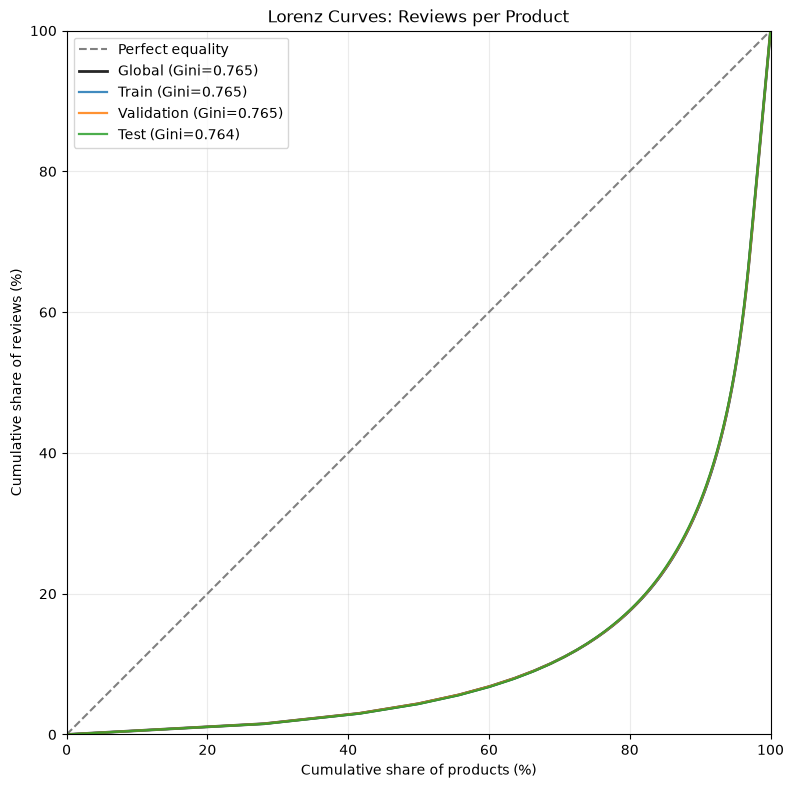

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Use the existing product-level counts and split mapping.
split_path = DATA_PROCESSED / "product_split.csv"

products = prod[["product_id", "n_rows"]].copy()
products["product_id"] = products["product_id"].astype("string")
products["n_rows"] = pd.to_numeric(products["n_rows"], errors="raise")

if products["product_id"].isna().any():
    raise ValueError("prod contains missing product_id values.")
if products["product_id"].duplicated().any():
    raise ValueError("prod must contain one row per product_id.")
if products["n_rows"].isna().any() or (products["n_rows"] <= 0).any():
    raise ValueError("n_rows must contain positive, non-missing values.")

products["n_rows"] = products["n_rows"].astype("int64")

split_map = pd.read_csv(split_path, dtype={"product_id": "string"})
split_map = split_map[["product_id", "split"]]

if split_map["product_id"].duplicated().any():
    raise ValueError("product_split.csv contains duplicate product_id values.")

joined = products.merge(
    split_map,
    on="product_id",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

unmatched = joined["_merge"] != "both"
if unmatched.any():
    print(joined.loc[unmatched].head())
    raise ValueError("The product counts and split mapping do not cover the same products.")

joined = joined.drop(columns="_merge")

expected_splits = {"train", "validation", "test"}
if set(joined["split"].unique()) != expected_splits:
    raise ValueError(f"Unexpected split values: {sorted(joined['split'].unique())}")

scope_frames = {"global": joined}
for split_name in ("train", "validation", "test"):
    scope_frames[split_name] = joined.loc[joined["split"] == split_name].copy()

global_product_count = len(joined)
global_review_count = int(joined["n_rows"].sum())


def summarize_concentration(frame):
    counts = np.sort(frame["n_rows"].to_numpy(dtype=np.float64))
    n_products = len(counts)
    n_reviews = float(counts.sum())

    # Gini coefficient; zero means equal reviews per product.
    ranks = np.arange(1, n_products + 1, dtype=np.float64)
    gini = (
        2 * np.dot(ranks, counts) / (n_products * n_reviews)
        - (n_products + 1) / n_products
    )
    gini = float(np.clip(gini, 0.0, 1.0))

    def top_product_review_share(product_fraction):
        n_top = max(1, int(np.ceil(n_products * product_fraction)))
        return 100.0 * counts[-n_top:].sum() / n_reviews

    return {
        "products": n_products,
        "product_share_of_global_pct": 100 * n_products / global_product_count,
        "reviews": int(n_reviews),
        "review_share_of_global_pct": 100 * n_reviews / global_review_count,
        "median_reviews_per_product": float(np.median(counts)),
        "p90_reviews_per_product": float(np.quantile(counts, 0.90)),
        "p99_reviews_per_product": float(np.quantile(counts, 0.99)),
        "max_reviews_per_product": int(counts[-1]),
        "gini": gini,
        "top_1pct_review_share_pct": top_product_review_share(0.01),
        "top_5pct_review_share_pct": top_product_review_share(0.05),
        "top_10pct_review_share_pct": top_product_review_share(0.10),
        "largest_product_review_share_pct": 100 * counts[-1] / n_reviews,
    }


metrics = pd.DataFrame(
    {
        scope: summarize_concentration(frame)
        for scope, frame in scope_frames.items()
    }
).T
metrics.index.name = "scope"

print("Concentration statistics:")
display(metrics.round(4))

# Show how each split's concentration metrics differ from the global dataset.
concentration_cols = [
    "gini",
    "top_1pct_review_share_pct",
    "top_5pct_review_share_pct",
    "top_10pct_review_share_pct",
]

deltas = metrics.loc[["train", "validation", "test"], concentration_cols].sub(
    metrics.loc["global", concentration_cols],
    axis="columns",
)
deltas = deltas.rename(
    columns={
        "gini": "gini_diff_vs_global",
        "top_1pct_review_share_pct": "top_1pct_share_diff_pp",
        "top_5pct_review_share_pct": "top_5pct_share_diff_pp",
        "top_10pct_review_share_pct": "top_10pct_share_diff_pp",
    }
)

print("Differences from global (share differences are percentage points):")
display(deltas.round(4))

# Plot Lorenz curves. Each curve sorts that scope's products from fewest
# to most reviews and shows cumulative product share vs cumulative review share.
fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(
    [0, 100], [0, 100],
    linestyle="--", color="gray", linewidth=1.5,
    label="Perfect equality",
)

colors = {
    "global": "black",
    "train": "tab:blue",
    "validation": "tab:orange",
    "test": "tab:green",
}

for scope, frame in scope_frames.items():
    counts = np.sort(frame["n_rows"].to_numpy(dtype=np.float64))
    cumulative_products = np.arange(len(counts) + 1) / len(counts)
    cumulative_reviews = np.concatenate(([0.0], np.cumsum(counts))) / counts.sum()
    cumulative_reviews[-1] = 1.0

    ax.plot(
        100 * cumulative_products,
        100 * cumulative_reviews,
        color=colors[scope],
        linewidth=2 if scope == "global" else 1.6,
        alpha=0.85,
        label=f"{scope.title()} (Gini={metrics.loc[scope, 'gini']:.3f})",
    )

ax.set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Cumulative share of products (%)",
    ylabel="Cumulative share of reviews (%)",
    title="Lorenz Curves: Reviews per Product",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()

REPORTS.mkdir(parents=True, exist_ok=True)
fig.savefig(
    REPORTS / "product_review_lorenz_by_split.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

metrics.to_csv(REPORTS / "product_concentration_by_split.csv")
deltas.to_csv(REPORTS / "product_concentration_differences_vs_global.csv")

# Top 10, products in comments share: names and some analysis

In [13]:

from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

PRODUCTS_CSV = ROOT / "data/raw/digikala-products.csv"
OUTPUT_CSV = REPORTS / "top10_most_commented_products.csv"

REPORTS.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 2. Top 10 products
# --------------------------------------------------

top10_ids = [
    "5715766",
    "4012333",
    "7291752",
    "82098",
    "4545846",
    "471187",
    "126148",
    "4411958",
    "11788028",
    "1518148",
]

# --------------------------------------------------
# 3. Read product information
# --------------------------------------------------

products = pd.read_csv(
    PRODUCTS_CSV,
    usecols=["id", "title_fa"],
    dtype={"id": "string"}
)

products = products.drop_duplicates(subset="id", keep="first")


# --------------------------------------------------
# 4. Global comment-length statistics
# --------------------------------------------------

global_stats = cur.execute(f"""
    SELECT
        COUNT(*) AS total_comments,
        AVG(LENGTH(body)) AS global_mean_length,
        MEDIAN(LENGTH(body)) AS global_median_length
    FROM {CLEAN_TABLE}
    WHERE body IS NOT NULL
""").df().iloc[0]


# --------------------------------------------------
# 5. Product-level comment statistics
# --------------------------------------------------

top10_sql = ", ".join(f"'{pid}'" for pid in top10_ids)

product_stats = cur.execute(f"""
    SELECT
        product_id,
        COUNT(*) AS n_comments,
        AVG(LENGTH(body)) AS mean_comment_length,
        MEDIAN(LENGTH(body)) AS median_comment_length
    FROM {CLEAN_TABLE}
    WHERE product_id IN ({top10_sql})
      AND body IS NOT NULL
    GROUP BY product_id
""").df()

# Keep product IDs consistent for merging
product_stats["product_id"] = product_stats["product_id"].astype("string")

# --------------------------------------------------
# 6. Merge product titles
# --------------------------------------------------

result = product_stats.merge(
    products,
    left_on="product_id",
    right_on="id",
    how="left"
)

result = result.rename(columns={
    "title_fa": "product_name"
})


# --------------------------------------------------
# 7. Calculate comment share and length differences
# --------------------------------------------------

total_comments = global_stats["total_comments"]
global_mean = global_stats["global_mean_length"]
global_median = global_stats["global_median_length"]

result["comment_share_pct"] = (
    result["n_comments"] / total_comments * 100
)

result["mean_diff_from_global_mean_pct"] = (
    (result["mean_comment_length"] - global_mean)
    / global_mean * 100
)

result["mean_diff_from_global_median_pct"] = (
    (result["mean_comment_length"] - global_median)
    / global_median * 100
)


# --------------------------------------------------
# 8. Final table
# --------------------------------------------------

result = result[[
    "product_name",
    "product_id",
    "n_comments",
    "comment_share_pct",
    "mean_comment_length",
    "mean_diff_from_global_mean_pct",
    "mean_diff_from_global_median_pct",
]]

result = result.sort_values(
    "n_comments",
    ascending=False
).reset_index(drop=True)

# Round numerical columns
numeric_cols = result.select_dtypes(include="number").columns
result[numeric_cols] = result[numeric_cols].round(2)

# --------------------------------------------------
# 9. Save CSV
# --------------------------------------------------

result.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Global comment statistics:")
print(f"Total comments: {total_comments:,}")
print(f"Global mean length: {global_mean:.2f}")
print(f"Global median length: {global_median:.2f}")

print("\nTop 10 most-commented products:")
print(result.to_string(index=False))

print(f"\nSaved to: {OUTPUT_CSV}")


Global comment statistics:
Total comments: 6,151,947.0
Global mean length: 47.84
Global median length: 29.00

Top 10 most-commented products:
                                                                           product_name product_id  n_comments  comment_share_pct  mean_comment_length  mean_diff_from_global_mean_pct  mean_diff_from_global_median_pct
                              فلوئید ضد آفتاب مای مدل Hyaluronic Acid حجم 50 میلی لیتر     5715766         233                0.0                61.05                           27.61                            110.52
تونر پاک کننده صورت لافارر مدل مولتی اکتیو مناسب پوست های چرب و مختلط حجم 170 میلی لیتر    4012333         227                0.0                45.41                           -5.07                             56.60
                                  کرم مرطوب کننده و آبرسان ایباگ مدل شیر گاو وزن 80 گرم    7291752         224                0.0                41.33                          -13.62                         

### Adding products short name to the table

In [14]:

# Short product names
short_names = {
    "5715766": "ضد آفتاب مای",
    "4012333": "تونر لافارر",
    "7291752": "مرطوب‌کننده ایباگ",
    "82098": "شامپو ضد ریزش فولیکا",
    "4545846": "آبرسان راکوتن",
    "471187": "شامپو ضد ریزش سریتا",
    "126148": "رول ضد تعریق شون",
    "4411958": "فوم شستشوی ویتالیر",
    "11788028": "مرطوب‌کننده درمالیفت",
    "1518148": "پد پاک‌کننده آرایش ناژه",
}

# Add short name as the first column
result.insert(
    0,
    "product_short_name",
    result["product_id"].astype(str).map(short_names)
)

# Save updated CSV
result.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)

print(result[["product_short_name", "product_id"]].to_string(index=False))
print(f"\nUpdated file saved to: {OUTPUT_CSV}")


     product_short_name product_id
           ضد آفتاب مای    5715766
            تونر لافارر    4012333
      مرطوب‌کننده ایباگ    7291752
   شامپو ضد ریزش فولیکا      82098
          آبرسان راکوتن    4545846
    شامپو ضد ریزش سریتا     471187
       رول ضد تعریق شون     126148
     فوم شستشوی ویتالیر    4411958
پد پاک‌کننده آرایش ناژه    1518148
   مرطوب‌کننده درمالیفت   11788028

Updated file saved to: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/top10_most_commented_products.csv
